In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Install ultralytics — covers all YOLO versions v5 through v12
%pip install -q ultralytics matplotlib Pillow

import ultralytics
print(f' ultralytics version: {ultralytics.__version__}')

 ultralytics version: 8.4.21


In [12]:
# setup
MODEL_TYPE = "yolov12"

WEIGHTS_PATH = '/content/drive/MyDrive/YOLO_Tomato_Project/training_runs/yolo12_lr0.001/weights/best.pt'

SOURCE = '/content/drive/MyDrive/YOLO_Tomato_Project/datasets/test/images/IMG_0219_JPG.rf.c8d288f364390a28656a50ed7415713a.jpg'

SAVE_DIR = "/content/drive/MyDrive/MCE531/YOLO_Tomato_Project/results"

CONF_THRESHOLD = 0.25

IMGSZ = 640

print('  Configuration loaded:')
print(f'   MODEL_TYPE    : {MODEL_TYPE}')
print(f'   WEIGHTS_PATH  : {WEIGHTS_PATH}')
print(f'   SOURCE        : {SOURCE}')
print(f'   SAVE_DIR      : {SAVE_DIR}')
print(f'   CONF          : {CONF_THRESHOLD}')
print(f'   IMGSZ         : {IMGSZ}')

  Configuration loaded:
   MODEL_TYPE    : yolov12
   WEIGHTS_PATH  : /content/drive/MyDrive/YOLO_Tomato_Project/training_runs/yolo12_lr0.001/weights/best.pt
   SOURCE        : /content/drive/MyDrive/YOLO_Tomato_Project/datasets/test/images/IMG_0219_JPG.rf.c8d288f364390a28656a50ed7415713a.jpg
   SAVE_DIR      : /content/drive/MyDrive/MCE531/YOLO_Tomato_Project/results
   CONF          : 0.25
   IMGSZ         : 640


In [10]:
import sys
import tempfile
import urllib.request
from ultralytics import YOLO

weights_path = WEIGHTS_PATH

if weights_path.startswith('http://') or weights_path.startswith('https://'):
    print(f'[INFO] Downloading weights from URL …')
    tmp = tempfile.NamedTemporaryFile(suffix='.pt', delete=False)
    tmp.close()
    try:
        urllib.request.urlretrieve(weights_path, tmp.name)
        weights_path = tmp.name
        print(f'[INFO] Saved to: {weights_path}')
    except Exception as e:
        print(f' Download failed: {e}')
        raise

import os
if not os.path.isfile(weights_path):
    print(f' Weights file not found: "{weights_path}"')
    print('   → Make sure Drive is mounted (Cell 1) and the path in CONFIG (Cell 3) is correct.')
    raise FileNotFoundError(weights_path)

model = YOLO(weights_path)

print(f'\n {MODEL_TYPE.upper()} model loaded successfully!')
print(f'   Classes ({len(model.names)}): {list(model.names.values())}')


 YOLOV12 model loaded successfully!
   Classes (7): ['Bacterial Spot', 'Early_Blight', 'Healthy', 'Late_blight', 'Leaf Mold', 'Target_Spot', 'black spot']


In [13]:
from pathlib import Path

SUPPORTED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}
source = SOURCE

if source.startswith('http://') or source.startswith('https://'):
    ext = Path(source).suffix.lower() or '.jpg'
    tmp_img = tempfile.NamedTemporaryFile(suffix=ext, delete=False)
    tmp_img.close()
    print(f'[INFO] Downloading image from URL …')
    urllib.request.urlretrieve(source, tmp_img.name)
    source = tmp_img.name
    print(f' Image saved to: {source}')


elif os.path.isdir(source):
    images = [f for f in Path(source).iterdir() if f.suffix.lower() in SUPPORTED_EXTS]
    if not images:
        raise FileNotFoundError(f'No supported images found in: {source}')
    print(f' Folder source: {len(images)} image(s) found in "{source}"')

elif os.path.isfile(source):
    print(f' Single image source: {source}')

else:
    raise FileNotFoundError(f'Source not found: "{source}" — check CONFIG (Cell 3)')

RESOLVED_SOURCE = source
print(f'\n   Resolved source → {RESOLVED_SOURCE}')

 Single image source: /content/drive/MyDrive/YOLO_Tomato_Project/datasets/test/images/IMG_0219_JPG.rf.c8d288f364390a28656a50ed7415713a.jpg

   Resolved source → /content/drive/MyDrive/YOLO_Tomato_Project/datasets/test/images/IMG_0219_JPG.rf.c8d288f364390a28656a50ed7415713a.jpg


In [14]:
os.makedirs(SAVE_DIR, exist_ok=True)

print(f'[INFO] Running {MODEL_TYPE.upper()} inference …\n')

results = model.predict(
    source=RESOLVED_SOURCE,
    imgsz=IMGSZ,           # 640 — fixed per project brief
    conf=CONF_THRESHOLD,
    save=True,             # saves annotated images
    project=SAVE_DIR,
    name='predict',
    exist_ok=True,
    verbose=False,
)

print(f' Inference complete — {len(results)} image(s) processed.')
print(f'   Annotated images saved to: {os.path.join(SAVE_DIR, "predict")}')

[INFO] Running YOLOV12 inference …

Results saved to /content/drive/MyDrive/MCE531/YOLO_Tomato_Project/results/predict
 Inference complete — 1 image(s) processed.
   Annotated images saved to: /content/drive/MyDrive/MCE531/YOLO_Tomato_Project/results/predict


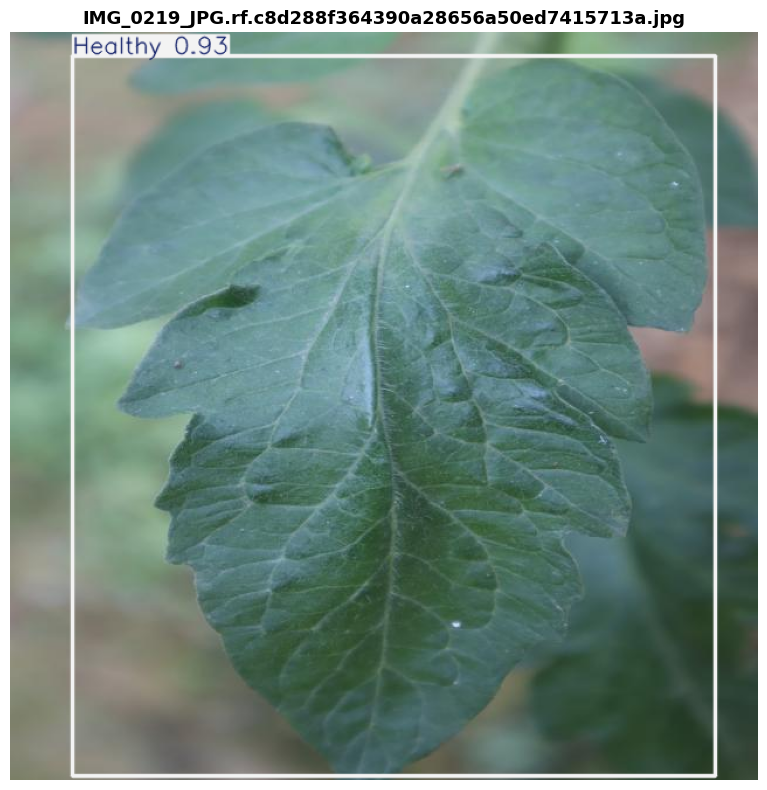

In [15]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

for result in results:
    annotated = result.plot()           # returns a BGR numpy array
    rgb = annotated[:, :, ::-1]         # convert BGR → RGB

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(rgb)
    ax.axis('off')
    ax.set_title(Path(result.path).name, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()